# Cross-Modal Retrieval of Mobile App Screens and Text Summaries

**Course:** COMP 1030 Multimodal Data Analytics, Project 2.2 (implementation of the Group 21 proposal)
**Dataset:** RICO-Screen2Words (`rootsautomation/RICO-Screen2Words`, CC BY 4.0 annotations)
**Task:** retrieve the correct screen for a text summary (text→screen) and the correct summary for a screen (screen→text).

This notebook is the experiment report. The reusable code lives in the `s2w/` package of this repository; the notebook calls it, prints every table and draws every figure.

| Proposal commitment / rubric item | Where |
|---|---|
| Data quality assessment and preprocessing (both modalities) | Sections 2–4 |
| Exclude screens with personal information | Section 4 |
| Split that groups apps linked by near-duplicate screens (cosine > 0.95) | Section 5 |
| Feature extraction selection: ResNet-50 vs ViT-B/16, BERT mean vs [CLS] | Section 6 |
| Ridge baseline, early-fusion MLP, contrastive dual encoder (all 5 captions as positives) | Sections 7–8 |
| Overfitting assessment and regularisation ablation | Section 8 |
| Contrastive retrieval + early-fusion re-ranking | Section 9 |
| CLIP as an external reference only | Section 10 |
| Recall@1/5/10, MRR, median rank, both directions; relaxed metric for generic captions | Section 11 |
| Bootstrap confidence intervals and the success criterion | Section 12 |
| Bias: macro-averaged per-category recall | Section 13 |
| Failure analysis: generic captions | Section 14 |
| Scalability (query cost vs gallery size) | Section 15 |
| Sensitivity to the near-duplicate threshold | Section 16 |

**How to run:** Colab → Runtime → Change runtime type → **T4 GPU**, then Runtime → Run all (about 60–90 minutes the first time; extracted features are cached on Google Drive, so reruns take about 30 minutes). Every number and figure is written to `results/`.

In [1]:
# Get the s2w package: use it if this notebook runs inside the repository, otherwise clone the repository.
import os, sys, subprocess
REPO_URL = "https://github.com/Riya-coder02/s2w-cross-modal-retrieval.git"   # <- set your GitHub username
if not os.path.isdir("s2w"):
    repo_dir = REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
    if not os.path.isdir(repo_dir):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir(repo_dir)
sys.path.insert(0, os.getcwd())

try:            # cache extracted features on Google Drive so a disconnect does not repeat the extraction
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except Exception:
    IN_COLAB = False
import importlib.util
if importlib.util.find_spec("datasets") is None:          # Colab ships everything else
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets"], check=True)
print("Working directory:", os.getcwd(), "| Colab:", IN_COLAB)

Mounted at /content/drive
Working directory: /content/s2w-cross-modal-retrieval | Colab: True


## 0. Configuration

In [2]:
import re, gc, json, math, textwrap, platform, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
from IPython.display import display

from s2w import data, features, splits, tensors, models, training, evaluation
from s2w.utils import DEVICE, Reporter, seed_everything, timer, gpu_reset, gpu_peak_gb
from s2w.data import IMG_COL, APP_COL, CAT_COL, ID_COL

warnings.filterwarnings("ignore")

DATASET_ID   = "rootsautomation/RICO-Screen2Words"
SEED         = 42                 # split / sampling seed
SEEDS        = [0, 1, 2]          # model training seeds (mean ± sd reported)
IMAGE_ENCODERS = ["resnet50", "vit_b_16"]   # compared in Section 6; the winner (on validation) is used downstream
BATCH_IMG, BATCH_TXT, NUM_WORKERS = 64, 512, 2
DUP_THRESHOLD   = 0.95            # proposal: group apps linked by near-duplicate screens (ResNet-50 cosine)
SENS_THRESHOLD  = 0.98            # sensitivity analysis (Section 16)
MAX_GROUP_SHARE = 0.05            # groups larger than this share of screens are kept in train
VAL_SHARE, TEST_SHARE = 0.10, 0.10
EPOCHS, PATIENCE, BATCH = 60, 8, 256
ALPHAS = [1e1, 1e2, 1e3, 1e4, 3e4, 1e5, 3e5, 1e6]       # ridge penalty grid
RERANK_K_GRID, RERANK_ALPHA_GRID = [20, 50, 100], [0.25, 0.5, 0.75, 1.0]
N_BOOT       = 1000
MIN_CAT_TEST = 10
LAT_GALLERIES = [1_000, 10_000, 100_000, 1_000_000]
RUN_CLIP_REFERENCE = True
FORCE_RECOMPUTE_FEATURES = False

# Screens with readable personal information found in the manual review (Section 4); removed after the split.
EXCLUDE_SCREEN_IDS = [11972, 13105, 5986, 15938]   # phone number, named investment accounts, dating-profile faces, name + date of birth

# Model configurations (Section 8). Contrastive: C0 = pilot setting, C1 adds all captions as positives with
# identical-text masking, C2 adds stronger regularisation. Early fusion: E0 = pilot setting, E1 regularised.
CONFIGS = {
    ("contrastive", "C0 pilot"):          dict(multi_pos=False, p=0.3, p_in=0.0, wd=0.01, lr=1e-3),
    ("contrastive", "C1 multi-positive"): dict(multi_pos=True,  p=0.3, p_in=0.0, wd=0.01, lr=1e-3),
    ("contrastive", "C2 regularised"):    dict(multi_pos=True,  p=0.5, p_in=0.2, wd=0.05, lr=1e-3),
    ("early", "E0 pilot"):                dict(k_neg=7, p=0.3, p_in=0.0, wd=0.01, lr=1e-3),
    ("early", "E1 regularised"):          dict(k_neg=7, p=0.5, p_in=0.2, wd=0.05, lr=1e-3),
}

R = Reporter("results", "private_outputs")      # private_outputs holds screenshots: git-ignored, never commit
CACHE = Path("/content/drive/MyDrive/s2w_cache") if IN_COLAB else Path("cache")
CACHE.mkdir(parents=True, exist_ok=True)
PALETTE = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2", "#937860", "#DA8BC3", "#8C8C8C"]
sns.set_theme(style="whitegrid", palette=PALETTE, font_scale=1.0)
seed_everything(SEED)

R.rec("python", platform.python_version()); R.rec("torch", torch.__version__); R.rec("device", DEVICE)
if DEVICE == "cuda":
    R.rec("gpu_name", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU. Use Runtime > Change runtime type > T4 GPU, or extraction will take hours.")

[result] python = 3.13.16
[result] torch = 2.14.1+cu130
[result] device = cuda
[result] gpu_name = Tesla T4


## 1. Load the dataset

Only the screenshot column is kept as images; icon and semantic-render images and the large view-hierarchy JSON strings are dropped at load time to stay within free Colab memory. The dataset's own train/val/test splits are **not** used: Section 5 builds a leakage-aware split.

In [3]:
meta, ds_img, original_splits = data.load_screen2words(DATASET_ID)
R.rec("original_splits", original_splits)
print(meta.drop(columns=["captions"]).head(3).T)

README.md:   0%|          | 0.00/6.13k [00:00<?, ?B/s]

data/train-00000-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  216MB            

data/train-00000-of-00008.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  219MB            

data/train-00001-of-00008.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  225MB            

... (19 outputs left out)

Generating train split:   0%|          | 0/15743 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/2364 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/4310 [00:00<?, ? examples/s]

[result] original_splits = {'train': 15743, 'val': 2364, 'test': 4310}
                                                                     0  \
screenId                                                             2   
file_name                                                   rico/2.jpg   
app_package_name                                  yong.app.videoeditor   
play_store_name                                   Video Maker Pro Free   
category                                       Video Players & Editors   
average_rating                                                     3.4   
number_of_ratings                                               100637   
number_of_downloads                           5,000,000 - 10,000,000     
file_name_icon                     rico_icons/yong.app.videoeditor.png   
file_name_semantic                     rico_semantic_annotations/2.png   
caps_raw             [notification displaying a calendar with done ...   
row                                      

## 2. Data quality assessment: text and metadata

Caption counts, empty or duplicated captions, caption length, vocabulary, **caption reuse across screens** (generic captions such as "login page" fit many screens and cap what any model can achieve), app and category balance, and malformed metadata.

In [4]:
cap_df = pd.DataFrame([(r, c) for r, cl in zip(meta["row"], meta["caps_raw"]) for c in cl], columns=["row", "caption"])
cap_df["norm"] = cap_df["caption"].map(data.norm)
cap_df["n_words"] = cap_df["caption"].str.split().str.len()
caps_per = meta["caps_raw"].str.len()

R.rec("n_screens", len(meta)); R.rec("n_captions", len(cap_df))
R.rec("captions_per_screen_min_max", [caps_per.min(), caps_per.max()])
R.rec("duplicate_screen_ids", int(meta[ID_COL].duplicated().sum()))
R.rec("empty_captions", int((cap_df["norm"] == "").sum()))
R.rec("words_median_p95_max", [cap_df["n_words"].median(), cap_df["n_words"].quantile(0.95), cap_df["n_words"].max()])
R.rec("vocab_size", len(Counter(w for n in cap_df["norm"] for w in n.split())))
screens_per_text = cap_df.groupby("norm")["row"].nunique()
R.rec("share_captions_reused_across_screens", cap_df["norm"].map(screens_per_text).gt(1).mean())
R.rec("duplicate_captions_within_screen", sum(len(cl) - len({data.norm(c) for c in cl}) for cl in meta["caps_raw"]))

meta["category_clean"], bad_cat = data.clean_category(meta[CAT_COL])
R.rec("malformed_category_labels", meta.loc[bad_cat, CAT_COL].value_counts().to_dict())
cat_counts = meta["category_clean"].value_counts()
R.rec("n_categories", len(cat_counts))
R.rec("category_largest_smallest", [cat_counts.index[0], int(cat_counts.iloc[0]), cat_counts.index[-1], int(cat_counts.iloc[-1])])
spa = meta.groupby(APP_COL).size()
R.rec("n_apps", len(spa)); R.rec("screens_per_app_median_max", [spa.median(), spa.max()])
R.table(screens_per_text.sort_values(ascending=False).head(12).rename("screens sharing caption").to_frame(),
        "t1_most_reused_captions", "Table 1: most reused (least specific) captions")

[result] n_screens = 22417
[result] n_captions = 112085
[result] captions_per_screen_min_max = [5, 5]
[result] duplicate_screen_ids = 0
[result] empty_captions = 0
[result] words_median_p95_max = [7.0, 10.0, 12]
[result] vocab_size = 6787
[result] share_captions_reused_across_screens = 0.3179
[result] duplicate_captions_within_screen = 979
[result] malformed_category_labels = {'000 - 1': 1}
[result] n_categories = 28
[result] category_largest_smallest = ['Shopping', 1648, 'Unknown', 1]
[result] n_apps = 6269
[result] screens_per_app_median_max = [2.0, 45]
Table 1: most reused (least specific) captions


,screens sharing caption
norm,
welcome page,635
login page,389
sign in page,346
settings page,296
sign up page,250
display of a pop up,208
home page,202
page displaying different options,192
list of options available in the app,149


## 3. Preprocessing and feature extraction

**Text.** Whitespace is normalised and duplicate captions inside one screen are removed (they add no information and would be double-counted as positives). The BERT token limit is chosen from the data (99.9th percentile, at least 16). Frozen **BERT-base** produces both mean-pooled and [CLS] features; Section 6 picks one on validation data.

**Images.** Screens are resized to 224×224 **without cropping** (screens are tall; cropping would cut navigation bars and buttons) and ImageNet-normalised. Two frozen ImageNet encoders are extracted: **ResNet-50** (convolutional, 2048-d, strong local texture features) and **ViT-B/16** (transformer, 768-d, global attention over 16×16 patches, which may suit layout-like images). The ResNet pass also records image quality for **every** screenshot: decode failures, resolution, near-blank screens and a difference hash for exact duplicates.

Freezing the encoders keeps training within a free T4 and follows the "pretrained encoder + small trainable head" pattern; all features are cached on Drive.

In [5]:
CI = data.build_caption_index(meta)
R.rec("captions_after_within_screen_dedup", len(CI.caps))

from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("bert-base-uncased")
lens = np.array([len(x) for x in tok(CI.caps, add_special_tokens=True, truncation=False)["input_ids"]])
MAX_LEN = int(max(16, np.ceil(np.percentile(lens, 99.9))))
R.rec("bert_tokens_median_p99", [np.median(lens), np.percentile(lens, 99)]); R.rec("MAX_LEN", MAX_LEN)
R.rec("share_captions_truncated", float((lens > MAX_LEN).mean()))

IMG, TIMING = {}, {}
# ResNet-50 + BERT (+ image quality) share one cache file (compatible with earlier runs of this notebook)
cache_main = CACHE / "features_full.npz"
if cache_main.exists() and not FORCE_RECOMPUTE_FEATURES:
    z = np.load(cache_main, allow_pickle=True)
    assert z["img"].shape[0] == len(meta) and z["txt_mean"].shape[0] == len(CI.caps), "cache mismatch: set FORCE_RECOMPUTE_FEATURES=True"
    IMG["resnet50"], txt_mean, txt_cls = z["img"], z["txt_mean"], z["txt_cls"]
    img_info, t = pd.DataFrame(json.loads(str(z["img_info"]))), json.loads(str(z["timing"]))
    TIMING["resnet50"], TIMING["bert"] = t["img_s"], t["txt_s"]
    print("Loaded cached ResNet-50 and BERT features")
else:
    with timer() as t_i:
        IMG["resnet50"], img_info = features.extract_image_features(ds_img, meta["row"].values, "resnet50", BATCH_IMG, NUM_WORKERS, with_quality=True)
    with timer() as t_t:
        txt_mean, txt_cls = features.extract_text_features(CI.caps, tok, MAX_LEN, BATCH_TXT)
    TIMING["resnet50"], TIMING["bert"] = t_i["s"], t_t["s"]
    np.savez(cache_main, img=IMG["resnet50"], txt_mean=txt_mean, txt_cls=txt_cls,
             img_info=json.dumps(img_info.to_dict(orient="list")),
             timing=json.dumps({"img_s": t_i["s"], "txt_s": t_t["s"], "peak_img_gb": float("nan"), "peak_txt_gb": float("nan")}))
for enc in IMAGE_ENCODERS:
    if enc in IMG:
        continue
    f = CACHE / f"features_{enc}.npz"
    if f.exists() and not FORCE_RECOMPUTE_FEATURES:
        z = np.load(f); IMG[enc], TIMING[enc] = z["img"], float(z["seconds"]); print("Loaded cached", enc)
    else:
        with timer() as t_e:
            IMG[enc], _ = features.extract_image_features(ds_img, meta["row"].values, enc, BATCH_IMG, NUM_WORKERS)
        TIMING[enc] = t_e["s"]; np.savez(f, img=IMG[enc], seconds=t_e["s"])
TXT = {"mean": txt_mean, "cls": txt_cls}
R.rec("feature_extraction_seconds", TIMING)
R.rec("feature_dims", {**{k: v.shape[1] for k, v in IMG.items()}, "bert": txt_mean.shape[1]})

[result] captions_after_within_screen_dedup = 111106


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[result] bert_tokens_median_p99 = [9.0, 13.0]
[result] MAX_LEN = 16
[result] share_captions_truncated = 0.0001
Loaded cached ResNet-50 and BERT features
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:03<00:00, 95.6MB/s]


vit_b_16:   0%|          | 0/351 [00:00<?, ?it/s]

[result] feature_extraction_seconds = {'resnet50': 684.5885, 'bert': 35.2671, 'vit_b_16': 481.7491}
[result] feature_dims = {'resnet50': 2048, 'vit_b_16': 768, 'bert': 768}


[result] corrupt_or_unreadable_images = 0
[result] image_resolutions = {'(1080, 1920)': 17422, '(540, 960)': 4995}
[result] near_blank_screens = 3
[result] screens_with_exact_duplicate_hash = 907
[result] exact_duplicate_share = 0.0405
[result] duplicate_hash_groups_spanning_apps = 176


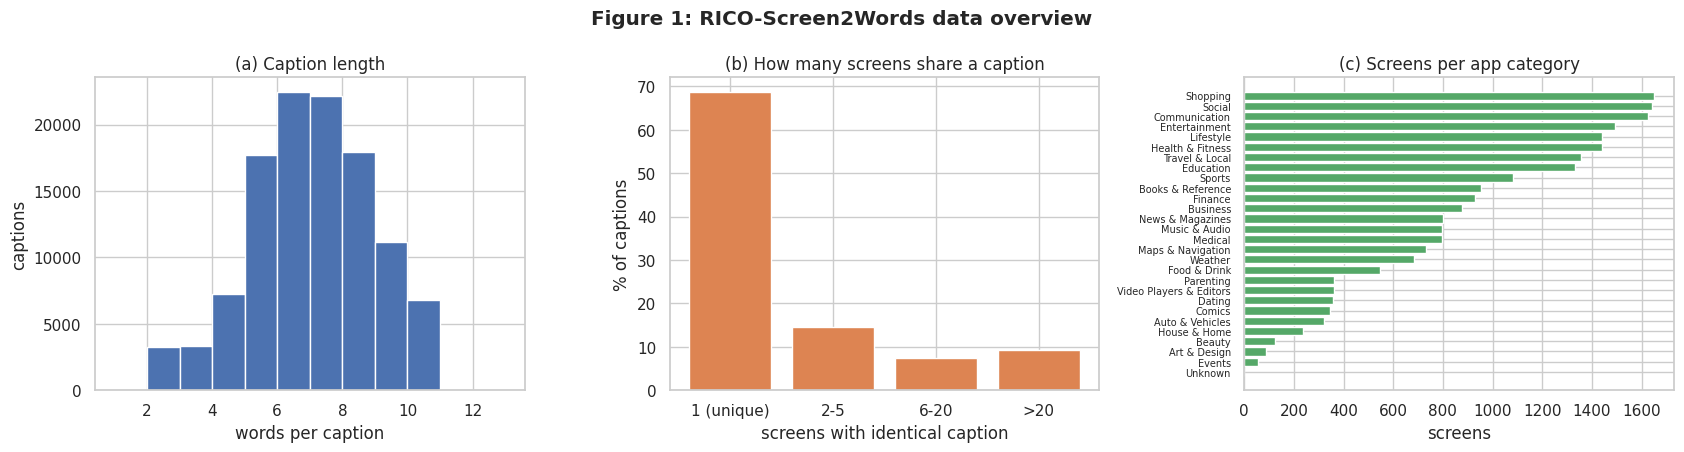

PosixPath('results/figures/fig1_data_overview.png')

In [6]:
img_info["row"] = meta["row"].values
ok = img_info[img_info["ok"]]
R.rec("corrupt_or_unreadable_images", int((~img_info["ok"]).sum()))
R.rec("image_resolutions", ok.groupby(["w", "h"]).size().sort_values(ascending=False).head(3).to_dict())
R.rec("near_blank_screens", int((ok["gray_std"] < 3).sum()))
dup_hash = ok[ok.duplicated("dhash", keep=False)]
R.rec("screens_with_exact_duplicate_hash", len(dup_hash)); R.rec("exact_duplicate_share", len(dup_hash) / len(ok))
R.rec("duplicate_hash_groups_spanning_apps",
      int((dup_hash.merge(meta[["row", APP_COL]], on="row").groupby("dhash")[APP_COL].nunique() > 1).sum()))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].hist(cap_df["n_words"], bins=range(1, int(cap_df["n_words"].max()) + 2), color=PALETTE[0], edgecolor="white")
ax[0].set_title("(a) Caption length"); ax[0].set_xlabel("words per caption"); ax[0].set_ylabel("captions")
reuse = pd.cut(pd.Series(CI.screens_sharing), [0, 1, 5, 20, 1e9], labels=["1 (unique)", "2-5", "6-20", ">20"]).value_counts().sort_index()
ax[1].bar(reuse.index.astype(str), reuse.values / reuse.sum() * 100, color=PALETTE[1])
ax[1].set_title("(b) How many screens share a caption"); ax[1].set_xlabel("screens with identical caption"); ax[1].set_ylabel("% of captions")
cc = cat_counts.sort_values()
ax[2].barh(cc.index, cc.values, color=PALETTE[2]); ax[2].set_title("(c) Screens per app category"); ax[2].set_xlabel("screens")
ax[2].tick_params(axis="y", labelsize=7)
fig.suptitle("Figure 1: RICO-Screen2Words data overview", fontweight="bold"); fig.tight_layout()
R.fig(fig, "fig1_data_overview")

## 4. Privacy review and exclusions (ethics)

Automatic checks cannot read text inside screenshots, so screens are reviewed by eye. The grid shows 80 random screens with their `screenId`; any screen with **readable personal information** (names, account details, faces, phone numbers) is added to `EXCLUDE_SCREEN_IDS` in the configuration cell. The grid is saved only to the git-ignored `private_outputs/`, because screenshots may be copyrighted and may contain personal data.

Captions are scanned for e-mail addresses, phone numbers, URLs and handles. Screens depicting login, payment or messaging functions are **counted, not removed** (they are normal app screens) and are never shown in shared figures.

In [7]:
def review_grid(seed=0, n=40, cols=8):
    rows = np.random.default_rng(seed).choice(len(meta), n, replace=False)
    fig, axes = plt.subplots(int(np.ceil(n / cols)), cols, figsize=(cols * 2.2, np.ceil(n / cols) * 3.9))
    for a, r in zip(axes.flat, rows):
        a.imshow(ds_img[int(r)][IMG_COL].convert("RGB").resize((180, 320))); a.axis("off")
        a.set_title(f"id {meta.loc[r, ID_COL]}", fontsize=8)
    for a in axes.flat[len(rows):]: a.axis("off")
    fig.tight_layout(); R.fig(fig, f"privacy_review_seed{seed}", private=True)
for s in [0, 1]:
    review_grid(seed=s)

PII = {"email": r"[\w\.-]+@[\w\.-]+\.\w+", "phone": r"(?<!\d)\+?\d[\d\-\s().]{8,}\d(?!\d)",
       "url": r"(?:https?://|www\.)\S+", "handle": r"(?<!\w)@\w{3,}"}
R.rec("pii_regex_hits_in_captions", {k: int(cap_df["caption"].str.contains(p, regex=True).sum()) for k, p in PII.items()})
SENSITIVE = ["login", "log in", "sign in", "sign up", "password", "payment", "credit card", "account", "profile",
             "chat", "message", "bank", "wallet", "address", "phone number", "email"]
sens_pat = "|".join(re.escape(w) for w in SENSITIVE)
meta["sensitive_function"] = meta["caps"].map(lambda cl: any(re.search(sens_pat, c.lower()) for c in cl))
R.rec("share_screens_depicting_sensitive_functions", meta["sensitive_function"].mean())

meta["unusable"] = (~img_info["ok"].values) | (meta["n_caps"] == 0).values
meta["pii_excluded"] = meta[ID_COL].isin(EXCLUDE_SCREEN_IDS).values
R.rec("manual_review", {"screens_reviewed": 80, "with_personal_information": int(meta["pii_excluded"].sum())})
R.rec("excluded_screens", {"personal_information": int(meta["pii_excluded"].sum()), "unreadable_image": int((~img_info["ok"]).sum()),
                           "no_caption": int((meta["n_caps"] == 0).sum()), "total": int((meta["unusable"] | meta["pii_excluded"]).sum())})
kept = ~(meta["unusable"] | meta["pii_excluded"])
impact = pd.DataFrame({"screens": [len(meta), int(kept.sum())], "captions": [len(cap_df), int(meta.loc[kept, "n_caps"].sum())]},
                      index=["raw", "after cleaning and exclusions"])
impact["captions_kept_%"] = (impact["captions"] / impact["captions"].iloc[0] * 100).round(2)
R.table(impact, "t2_cleaning_impact", "Table 2: cleaning and exclusion impact")

[result] pii_regex_hits_in_captions = {'email': 0, 'phone': 0, 'url': 0, 'handle': 0}
[result] share_screens_depicting_sensitive_functions = 0.2471
[result] manual_review = {'screens_reviewed': 80, 'with_personal_information': 4}
[result] excluded_screens = {'personal_information': 4, 'unreadable_image': 0, 'no_caption': 0, 'total': 4}
Table 2: cleaning and exclusion impact


,screens,captions,captions_kept_%
raw,22417,112085,100.00
after cleaning and exclusions,22413,111086,99.11


[screenshot figure saved to private_outputs/ only; not shown, because screenshots may be copyrighted or contain personal data]


## 5. Leakage-aware split

The pilot split by app, yet test screens still had near-duplicates (cosine > 0.95) in training, mostly from *different* apps built on the same template; a model can then match a memorised twin, inflating scores.

Fix (as proposed): link two apps if any of their screens have ResNet-50 cosine similarity above `DUP_THRESHOLD`, and keep each connected group inside one split. Template-heavy screens can chain many apps into one very large component; components larger than `MAX_GROUP_SHARE` of the data go to training (where they cannot leak) and the remaining groups are shuffled into train/validation/test at 80/10/10 by screen count. Screens with personal information are removed **after** the split so the exclusion list does not reshuffle it. The split is fixed before any feature or model selection.

[result] screen_pairs_above_0.95 = 46219
Table 3: app groups formed by near-duplicate links


,groups,largest_group_screens,largest_group_share_%,groups_above_cap
threshold,,,,
0.95,3397,13822,61.66,1
0.97,4898,5995,26.74,1
0.98,5556,1188,5.30,1


[result] screens_forced_to_train = 13822
Table 4: train-test leakage under the two split strategies


,test_screens,near_dup_in_train_>0.95_%,near_dup_in_train_>0.98_%,median_nearest_train_cos,test_captions_seen_in_train_%
app-only split (pilot),2242,27.65,5.75,0.92,29.23
near-duplicate groups (cos>0.95),2242,0.00,0.00,0.87,30.08


[result] leakage_app_split = {'test_screens': 2242, 'near_dup_in_train_>0.95_%': 27.6539, 'near_dup_in_train_>0.98_%': 5.7538, 'median_nearest_train_cos': 0.9197, 'test_captions_seen_in_train_%': 29.2308}
[result] leakage_grouped_split = {'test_screens': 2242, 'near_dup_in_train_>0.95_%': 0.0, 'near_dup_in_train_>0.98_%': 0.0, 'median_nearest_train_cos': 0.8726, 'test_captions_seen_in_train_%': 30.0793}
Table 5: final split sizes


,screens,captions,apps
split,,,
test,2242,11094,935
train,17931,88903,4389
val,2240,11089,945


[result] split_sizes = {'test': 2242, 'train': 17931, 'val': 2240}


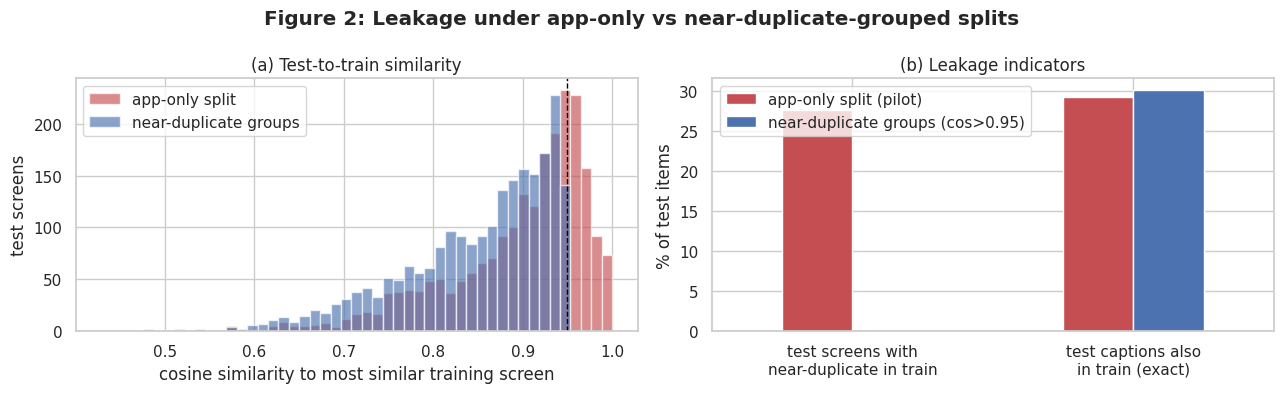

PosixPath('results/figures/fig2_split_leakage.png')

In [8]:
keep = np.where(~meta["unusable"].values)[0]
Fn = splits.normalised(IMG["resnet50"][keep])
app_codes, app_index = np.unique(meta[APP_COL].fillna("NA").astype(str).values[keep], return_inverse=True)
pairs = splits.near_duplicate_pairs(Fn, threshold=0.95)
R.rec("screen_pairs_above_0.95", len(pairs[0]))

comp = []
for t in [0.95, 0.97, 0.98]:
    sizes = pd.Series(splits.app_groups(pairs, app_index, t)[app_index]).value_counts()
    comp.append({"threshold": t, "groups": len(sizes), "largest_group_screens": int(sizes.iloc[0]),
                 "largest_group_share_%": round(sizes.iloc[0] / len(keep) * 100, 2),
                 "groups_above_cap": int((sizes > MAX_GROUP_SHARE * len(keep)).sum())})
R.table(pd.DataFrame(comp).set_index("threshold"), "t3_duplicate_groups", "Table 3: app groups formed by near-duplicate links")

kw = dict(val_share=VAL_SHARE, test_share=TEST_SHARE, seed=SEED)
split_app = splits.assign_split(app_index, **kw)                                       # pilot-style: group = app
split_grp, grp, forced_main = splits.grouped_split(pairs, app_index, DUP_THRESHOLD, MAX_GROUP_SHARE, **kw)
R.rec("screens_forced_to_train", forced_main)
mx_app, L_app = splits.leakage_report(Fn, split_app, keep, CI.owner, CI.textid)
mx_grp, L_grp = splits.leakage_report(Fn, split_grp, keep, CI.owner, CI.textid)
leak_tbl = pd.DataFrame([L_app, L_grp], index=["app-only split (pilot)", f"near-duplicate groups (cos>{DUP_THRESHOLD})"]).round(2)
R.table(leak_tbl, "t4_leakage", "Table 4: train-test leakage under the two split strategies")
R.rec("leakage_app_split", L_app); R.rec("leakage_grouped_split", L_grp)

meta["split"] = "excluded"
meta.loc[keep, "split"] = split_grp
meta.loc[meta["pii_excluded"], "split"] = "excluded"
split_tbl = meta[meta["split"] != "excluded"].groupby("split").agg(screens=("row", "size"), captions=("n_caps", "sum"), apps=(APP_COL, "nunique"))
R.table(split_tbl, "t5_split_sizes", "Table 5: final split sizes")
R.rec("split_sizes", split_tbl["screens"].to_dict())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
bins = np.linspace(min(mx_app.min(), mx_grp.min()), 1, 50)
ax[0].hist(mx_app, bins=bins, alpha=0.65, label="app-only split", color=PALETTE[3])
ax[0].hist(mx_grp, bins=bins, alpha=0.65, label="near-duplicate groups", color=PALETTE[0])
ax[0].axvline(DUP_THRESHOLD, color="k", ls="--", lw=1); ax[0].set_xlabel("cosine similarity to most similar training screen")
ax[0].set_ylabel("test screens"); ax[0].set_title("(a) Test-to-train similarity"); ax[0].legend()
leak_tbl[["near_dup_in_train_>0.95_%", "test_captions_seen_in_train_%"]].T.plot.bar(ax=ax[1], color=[PALETTE[3], PALETTE[0]], rot=0)
ax[1].set_ylabel("% of test items"); ax[1].set_title("(b) Leakage indicators")
ax[1].set_xticklabels(["test screens with\nnear-duplicate in train", "test captions also\nin train (exact)"])
fig.suptitle("Figure 2: Leakage under app-only vs near-duplicate-grouped splits", fontweight="bold"); fig.tight_layout()
R.fig(fig, "fig2_split_leakage")

## 6. Feature extraction selection (validation only)

**Metrics used throughout.** Recall@K (K = 1, 5, 10), mean reciprocal rank (MRR) and median rank in both directions. Screen→text is a hit if *any* caption of the screen is retrieved; text→screen is a hit if the source screen is retrieved. Ties count half. A **relaxed** Recall@10 also accepts items carrying a caption identical (after normalisation) to the query's, because 31.8% of captions are reused on other screens. Features are standardised with training statistics only.

**Selection.** Both image encoders are compared with both BERT poolings using (a) ridge regression over a wide penalty grid and (b) the contrastive dual encoder in its pilot setting (C0, three seeds). The encoder and pooling with the best **validation** Recall@10 for the contrastive model (the main learned model) are used for everything that follows. Test scores of the comparison are reported for completeness only.

resnet50  mean  ridge val 6.81  contrastive val 9.38
resnet50  cls   ridge val 6.64  contrastive val 8.84
vit_b_16  mean  ridge val 7.66  contrastive val 11.63
vit_b_16  cls   ridge val 6.96  contrastive val 10.55
Table 6: feature extraction selection (avg Recall@10; selection uses validation columns only)


ridge_alpha  ridge_val_R10  contrastive_val_R10  \
encoder  pooling                                                    
resnet50 mean           100.0           6.81                 9.38   
         cls           1000.0           6.64                 8.84   
vit_b_16 mean            10.0           7.66                11.63   
         cls             10.0           6.96                10.55   

                  contrastive_val_sd  ridge_test_i2t  ridge_test_t2i  \
encoder  pooling                                                       
resnet50 mean                   0.18            9.63            6.12   
         cls                    0.15            9.28            5.61   
vit_b_16 mean                   0.27            9.72            5.71   
         cls                    0.05            7.40            5.07   

                  contrastive_test_i2t  contrastive_test_t2i  
encoder  pooling                                              
resnet50 mean                     9.49                  8.77  
         cls                      9.13                  8.21  
vit_b_16 mean                    12.76                 10.98  
         cls                     10.84                 10.06

[result] image_encoder_chosen = vit_b_16
[result] bert_pooling_chosen = mean


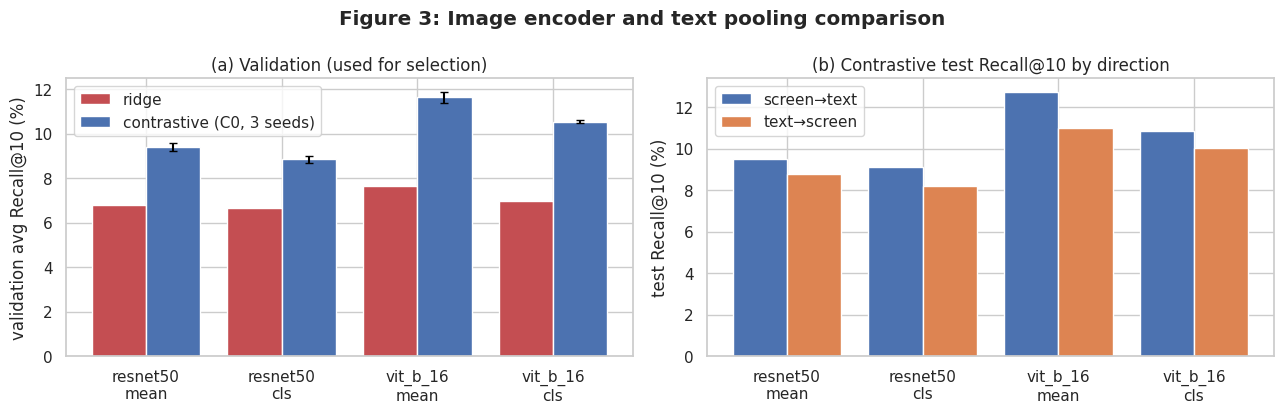

PosixPath('results/figures/fig3_feature_selection.png')

In [9]:
def split_tensors(img_name, pool, labels=None):
    lab = meta["split"].values if labels is None else labels
    return tensors.build_split_tensors(lab, meta["n_caps"].values, meta["cap_start"].values, CI.textid,
                                       IMG[img_name], TXT[pool], seed=SEED)

def fit_ridge(D, alphas=ALPHAS):
    """Choose alpha on validation; return (W, alpha, validation metrics)."""
    best = None
    for a in alphas:
        W = models.ridge_fit(D["train"]["XT"], D["train"]["XI"][D["train"]["cap2img"]], a)
        m = evaluation.evaluate(models.ridge_scores(W, D["val"]), D["val"])
        if best is None or m["avg_R10"] > best[2]["avg_R10"]:
            best = (W, a, m)
    return best

sel, ridge_grid = [], []
for enc in IMAGE_ENCODERS:
    for pool in ["mean", "cls"]:
        Dx = split_tensors(enc, pool)
        for a in ALPHAS:
            W = models.ridge_fit(Dx["train"]["XT"], Dx["train"]["XI"][Dx["train"]["cap2img"]], a)
            m = evaluation.evaluate(models.ridge_scores(W, Dx["val"]), Dx["val"])
            ridge_grid.append({"encoder": enc, "pooling": pool, "alpha": a, "val_avg_R10": m["avg_R10"]})
        Wr, ar, mr = fit_ridge(Dx)
        mt = evaluation.evaluate(models.ridge_scores(Wr, Dx["test"]), Dx["test"])
        runs = [training.train_model("contrastive", CONFIGS[("contrastive", "C0 pilot")], s, Dx, CI.n_text, EPOCHS, PATIENCE, BATCH) for s in SEEDS]
        ct = [evaluation.evaluate(r["model"].score_matrix(Dx["test"]["XI"], Dx["test"]["XT"]), Dx["test"]) for r in runs]
        sel.append({"encoder": enc, "pooling": pool, "ridge_alpha": ar, "ridge_val_R10": mr["avg_R10"],
                    "contrastive_val_R10": np.mean([r["best_val"] for r in runs]), "contrastive_val_sd": np.std([r["best_val"] for r in runs]),
                    "ridge_test_i2t": mt["i2t_R10"], "ridge_test_t2i": mt["t2i_R10"],
                    "contrastive_test_i2t": np.mean([m["i2t_R10"] for m in ct]), "contrastive_test_t2i": np.mean([m["t2i_R10"] for m in ct])})
        print(f"{enc:9s} {pool:4s}  ridge val {mr['avg_R10']:.2f}  contrastive val {sel[-1]['contrastive_val_R10']:.2f}")
        del Dx; gc.collect()
sel_df = pd.DataFrame(sel).set_index(["encoder", "pooling"])
R.table(sel_df.round(2), "t6_feature_selection", "Table 6: feature extraction selection (avg Recall@10; selection uses validation columns only)")
R.table(pd.DataFrame(ridge_grid).pivot_table(index=["encoder", "pooling"], columns="alpha", values="val_avg_R10").round(2),
        "t6b_ridge_alpha_grid", "Table 6b: ridge validation avg Recall@10 over the penalty grid", show=False)
ENC, POOL = sel_df["contrastive_val_R10"].idxmax()
R.rec("image_encoder_chosen", ENC); R.rec("bert_pooling_chosen", POOL)
R.rec("feature_selection", sel_df.reset_index().to_dict(orient="records"), show=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
lbl = [f"{e}\n{p}" for e, p in sel_df.index]; x = np.arange(len(lbl))
ax[0].bar(x - 0.2, sel_df["ridge_val_R10"], 0.4, label="ridge", color=PALETTE[3])
ax[0].bar(x + 0.2, sel_df["contrastive_val_R10"], 0.4, yerr=sel_df["contrastive_val_sd"], capsize=3, label="contrastive (C0, 3 seeds)", color=PALETTE[0])
ax[0].set_xticks(x); ax[0].set_xticklabels(lbl); ax[0].set_ylabel("validation avg Recall@10 (%)"); ax[0].set_title("(a) Validation (used for selection)"); ax[0].legend()
for k, (c, nm) in enumerate([("contrastive_test_i2t", "screen→text"), ("contrastive_test_t2i", "text→screen")]):
    ax[1].bar(x + (k - 0.5) * 0.4, sel_df[c], 0.4, label=nm, color=PALETTE[k])
ax[1].set_xticks(x); ax[1].set_xticklabels(lbl); ax[1].set_ylabel("test Recall@10 (%)"); ax[1].set_title("(b) Contrastive test Recall@10 by direction"); ax[1].legend()
fig.suptitle("Figure 3: Image encoder and text pooling comparison", fontweight="bold"); fig.tight_layout()
R.fig(fig, "fig3_feature_selection")

## 7. Main tensors and ridge baseline

All downstream models use the selected encoder and pooling. The ridge penalty is re-selected on validation for that combination (the grid is wide enough that the best value is not at its edge).

In [10]:
D = split_tensors(ENC, POOL)
W_ridge, ALPHA, _ = fit_ridge(D)
R.rec("ridge_alpha_chosen", ALPHA); R.rec("ridge_alpha_at_grid_edge", ALPHA in (ALPHAS[0], ALPHAS[-1]))
TEST = {}           # method -> list of per-seed test metrics (with per-query ranks)
g = torch.Generator().manual_seed(0)
TEST["Random"] = [evaluation.evaluate(torch.rand(len(D["test"]["rows"]), len(D["test"]["cap_ids"]), generator=g).to(DEVICE), D["test"], keep_ranks=True)]
TEST["Ridge regression"] = [evaluation.evaluate(models.ridge_scores(W_ridge, D["test"]), D["test"], keep_ranks=True)]
R.rec("test_gallery", {"screens": len(D["test"]["rows"]), "captions": len(D["test"]["cap_ids"])})

[result] ridge_alpha_chosen = 10.0
[result] ridge_alpha_at_grid_edge = True
[result] test_gallery = {'screens': 2242, 'captions': 11094}


## 8. Early fusion vs contrastive learning, and the overfitting ablation

**Early fusion (joint representation, `s2w.models.EarlyFusion`).** Projected image and caption features are **concatenated** and an MLP outputs one match score per pair, trained with binary cross-entropy against shuffled in-batch negatives; negatives carrying the same caption text as the positive are masked. Concatenation models feature interactions, but every query must be scored against every candidate.

**Contrastive dual encoder (coordinated representation, `s2w.models.DualEncoder`).** Separate projection heads map each modality into a shared L2-normalised space with a learnable temperature (CLIP; Radford et al., 2021), trained with symmetric InfoNCE (van den Oord et al., 2018). As proposed, **all captions of a screen are positives** (multi-positive InfoNCE, as in MIL-NCE; Miech et al., 2020), and captions with identical text are positives rather than false negatives. Gallery embeddings are pre-computed, so a query is one matrix product.

**Overfitting.** The pilot's contrastive model reached training recall 54 points above validation, measured on a training subset with the same gallery size as validation (genuine memorisation). The configurations in `CONFIGS` are compared with three seeds each; the final configuration per model is chosen on validation Recall@10 only. All runs use early stopping (patience 8).

C0 pilot           seed 0: best ep 23  val R@10  11.4  gap  30.6     13s  1.05M params
C0 pilot           seed 1: best ep 34  val R@10  12.0  gap  39.6     17s  1.05M params
C0 pilot           seed 2: best ep 13  val R@10  11.5  gap  18.9      9s  1.05M params
C1 multi-positive  seed 0: best ep 14  val R@10  11.8  gap  46.5     14s  1.05M params
C1 multi-positive  seed 1: best ep 12  val R@10  12.1  gap  41.7     12s  1.05M params
C1 multi-positive  seed 2: best ep 11  val R@10  12.4  gap  38.6     11s  1.05M params
C2 regularised     seed 0: best ep 36  val R@10  12.5  gap  32.7     26s  1.05M params
C2 regularised     seed 1: best ep 37  val R@10  12.8  gap  32.3     27s  1.05M params
C2 regularised     seed 2: best ep 18  val R@10  12.3  gap  21.6     16s  1.05M params
E0 pilot           seed 0: best ep 32  val R@10   8.6  gap   7.8    131s  1.31M params
E0 pilot           seed 1: best ep 32  val R@10   8.9  gap   6.9    131s  1.31M params
E0 pilot           seed 2: best ep 26  val 

val_avg_R10  train−val gap at best epoch  \
model       config                                                         
contrastive C0 pilot           11.63 ± 0.27                         29.7   
            C1 multi-positive  12.07 ± 0.23                         42.3   
            C2 regularised     12.56 ± 0.21                         28.9   
early       E0 pilot            8.75 ± 0.08                          6.7   
            E1 regularised      7.62 ± 0.23                          2.5   

                               train−val gap at last epoch  best epoch  \
model       config                                                       
contrastive C0 pilot                                  37.5          23   
            C1 multi-positive                         55.8          12   
            C2 regularised                            33.6          30   
early       E0 pilot                                   9.2          30   
            E1 regularised                             3.4          36   

                               train time (s)  params (M)  
model       config                                         
contrastive C0 pilot                       13        1.05  
            C1 multi-positive              12        1.05  
            C2 regularised                 23        1.05  
early       E0 pilot                      124        1.31  
            E1 regularised                142        1.31

[result] chosen_configs_by_validation = {'contrastive': 'C2 regularised', 'early': 'E0 pilot'}


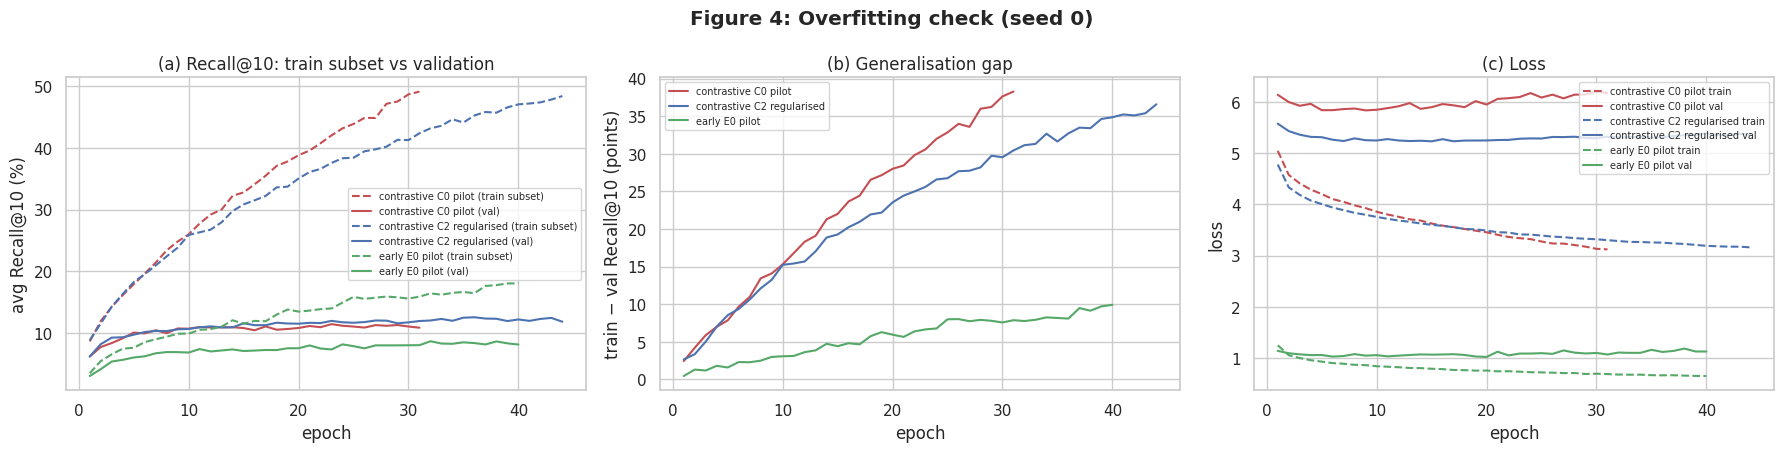

PosixPath('results/figures/fig4_learning_curves.png')

In [11]:
RUNS = {}
for (kind, name), cfg in CONFIGS.items():
    for sd in SEEDS:
        r = training.train_model(kind, cfg, sd, D, CI.n_text, EPOCHS, PATIENCE, BATCH)
        r["test"] = evaluation.evaluate(r["model"].score_matrix(D["test"]["XI"], D["test"]["XT"]), D["test"], keep_ranks=True)
        RUNS[(kind, name, sd)] = r
        print(f"{name:18s} seed {sd}: best ep {r['best_epoch']:2d}  val R@10 {r['best_val']:5.1f}  gap {r['gap']:5.1f}  {r['train_s']:5.0f}s  {r['params']/1e6:.2f}M params")

abl = []
for (kind, name), cfg in CONFIGS.items():
    rs = [RUNS[(kind, name, s)] for s in SEEDS]
    abl.append({"model": kind, "config": name,
                "val_avg_R10": f"{np.mean([r['best_val'] for r in rs]):.2f} ± {np.std([r['best_val'] for r in rs]):.2f}",
                "train−val gap at best epoch": round(np.mean([r["gap"] for r in rs]), 1),
                "train−val gap at last epoch": round(np.mean([r["final_gap"] for r in rs]), 1),
                "best epoch": round(np.mean([r["best_epoch"] for r in rs])), "train time (s)": round(np.mean([r["train_s"] for r in rs])),
                "params (M)": round(rs[0]["params"] / 1e6, 2), "_val": np.mean([r["best_val"] for r in rs])})
abl_df = pd.DataFrame(abl)
R.table(abl_df.drop(columns="_val").set_index(["model", "config"]), "t7_ablation_overfitting",
        "Table 7: configuration ablation and overfitting (validation; gap = train-subset R@10 minus validation R@10)")
BEST_CFG = {k: abl_df[abl_df["model"] == k].sort_values("_val", ascending=False)["config"].iloc[0] for k in ["contrastive", "early"]}
R.rec("chosen_configs_by_validation", BEST_CFG)
R.rec("ablation", abl_df.drop(columns="_val").to_dict(orient="records"), show=False)
TEST["Early fusion"] = [RUNS[("early", BEST_CFG["early"], s)]["test"] for s in SEEDS]
TEST["Contrastive"] = [RUNS[("contrastive", BEST_CFG["contrastive"], s)]["test"] for s in SEEDS]

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
show = [("contrastive", "C0 pilot", PALETTE[3]), ("contrastive", BEST_CFG["contrastive"], PALETTE[0]), ("early", BEST_CFG["early"], PALETTE[2])]
if show[0][1] == show[1][1]: show = show[1:]
for kind, name, c in show:
    h = RUNS[(kind, name, SEEDS[0])]["hist"]; lab = f"{kind} {name}"
    ax[0].plot(h["epoch"], h["train_R10"], c=c, ls="--", label=f"{lab} (train subset)"); ax[0].plot(h["epoch"], h["val_R10"], c=c, label=f"{lab} (val)")
    ax[1].plot(h["epoch"], h["train_R10"] - h["val_R10"], c=c, label=lab)
    ax[2].plot(h["epoch"], h["train_loss"], c=c, ls="--", label=f"{lab} train"); ax[2].plot(h["epoch"], h["val_loss"], c=c, label=f"{lab} val")
ax[0].set_title("(a) Recall@10: train subset vs validation"); ax[0].set_ylabel("avg Recall@10 (%)")
ax[1].set_title("(b) Generalisation gap"); ax[1].set_ylabel("train − val Recall@10 (points)")
ax[2].set_title("(c) Loss"); ax[2].set_ylabel("loss")
for a in ax: a.set_xlabel("epoch"); a.legend(fontsize=7)
fig.suptitle(f"Figure 4: Overfitting check (seed {SEEDS[0]})", fontweight="bold"); fig.tight_layout()
R.fig(fig, "fig4_learning_curves")

## 9. Contrastive retrieval + early-fusion re-ranking

Deployment idea from the proposal: the fast contrastive model retrieves the top-K candidates, then early fusion re-scores only those K. Inside the top-K the score is a weighted mix of the two z-scored model scores; K and the weight α are chosen on validation data.

In [12]:
mc0, me0 = RUNS[("contrastive", BEST_CFG["contrastive"], SEEDS[0])]["model"], RUNS[("early", BEST_CFG["early"], SEEDS[0])]["model"]
grid_df = pd.DataFrame([{"K": K, "alpha": a, "val_avg_R10": evaluation.evaluate_rerank(mc0, me0, D["val"], K, a)["avg_R10"]}
                        for K in RERANK_K_GRID for a in RERANK_ALPHA_GRID])
R.table(grid_df.pivot(index="K", columns="alpha", values="val_avg_R10").round(2), "t8_rerank_grid_val", "Table 8: re-ranking grid (validation avg Recall@10)")
bk = grid_df.loc[grid_df["val_avg_R10"].idxmax()]; RR_K, RR_ALPHA = int(bk["K"]), float(bk["alpha"])
R.rec("rerank_K_alpha", [RR_K, RR_ALPHA])
TEST["Contrastive + re-rank"] = [evaluation.evaluate_rerank(RUNS[("contrastive", BEST_CFG["contrastive"], s)]["model"],
                                                            RUNS[("early", BEST_CFG["early"], s)]["model"], D["test"], RR_K, RR_ALPHA, keep_ranks=True) for s in SEEDS]

Table 8: re-ranking grid (validation avg Recall@10)


alpha,0.25,0.50,0.75,1.00
K,,,,
20,12.70,12.27,11.98,11.68
50,12.79,12.10,11.14,10.16
100,12.79,12.19,11.08,9.43


[result] rerank_K_alpha = [50, 0.25]


## 10. CLIP zero-shot reference (not a main technique)

The brief allows CLIP only as a reference. Zero-shot CLIP ViT-B/32 scores the same test set; projections are called explicitly (`vision_model` → `visual_projection`, `text_model` → `text_projection`), which works across transformers versions.

In [13]:
if RUN_CLIP_REFERENCE:
    try:
        from transformers import CLIPModel, CLIPProcessor
        clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE).eval()
        proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
        te_rows, te_caps = D["test"]["rows"], [CI.caps[i] for i in D["test"]["cap_ids"]]
        with timer() as t_clip, torch.no_grad():
            ie = []
            for a in range(0, len(te_rows), 64):
                px = proc(images=[ds_img[int(r)][IMG_COL].convert("RGB") for r in te_rows[a:a + 64]], return_tensors="pt")["pixel_values"].to(DEVICE)
                ie.append(F.normalize(clip.visual_projection(clip.vision_model(pixel_values=px).pooler_output), dim=-1).float())
            tt = []
            for a in range(0, len(te_caps), 256):
                enc = proc.tokenizer(te_caps[a:a + 256], return_tensors="pt", padding=True, truncation=True, max_length=77).to(DEVICE)
                tt.append(F.normalize(clip.text_projection(clip.text_model(**enc).pooler_output), dim=-1).float())
            S_clip = torch.cat(ie) @ torch.cat(tt).T
        TEST["CLIP zero-shot (reference)"] = [evaluation.evaluate(S_clip, D["test"], keep_ranks=True)]
        R.rec("clip_seconds", t_clip["s"])
        del clip; gc.collect()
        if DEVICE == "cuda": torch.cuda.empty_cache()
    except Exception as e:
        print("CLIP reference skipped:", repr(e)); R.rec("clip_error", repr(e))

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

[result] clip_seconds = 70.1034


## 11. Test results

All choices above used validation data only; the test set is scored once per seed. Learned models show mean ± sd over three seeds. The best learned method is the one with the highest **validation** Recall@10.

Table 9: test results (Recall in %, MRR 0-1, MedR = median rank; relaxed = identical-caption matches accepted)


,i2t_R1,i2t_R5,i2t_R10,i2t_MRR,i2t_MedR,t2i_R1,t2i_R5,t2i_R10,t2i_MRR,t2i_MedR,i2t_R10_relaxed,t2i_R10_relaxed
method,,,,,,,,,,,,
Random,0.00,0.22,0.67,0.00,1529.00,0.04,0.31,0.54,0.00,1123.00,1.34,1.19
Ridge regression,1.38,5.53,9.72,0.04,230.00,0.74,3.15,5.71,0.03,266.00,10.21,10.11
Early fusion,1.32 ± 0.12,5.62 ± 0.16,9.43 ± 0.16,0.04 ± 0.00,170.50 ± 10.50,1.11 ± 0.07,4.95 ± 0.12,8.64 ± 0.13,0.04 ± 0.00,144.33 ± 2.05,9.71 ± 0.35,13.30 ± 0.16
Contrastive,2.30 ± 0.08,8.40 ± 0.20,13.51 ± 0.16,0.06 ± 0.00,122.50 ± 1.47,2.00 ± 0.05,7.37 ± 0.18,12.34 ± 0.13,0.06 ± 0.00,118.00 ± 2.83,16.06 ± 0.06,17.59 ± 0.23
Contrastive + re-rank,2.32 ± 0.18,8.31 ± 0.39,13.54 ± 0.34,0.06 ± 0.00,122.50 ± 1.47,2.01 ± 0.05,7.52 ± 0.10,12.53 ± 0.30,0.06 ± 0.00,118.00 ± 2.83,16.09 ± 0.41,17.99 ± 0.48
CLIP zero-shot (reference),13.60,29.44,37.96,0.22,25.00,7.20,16.39,21.93,0.12,111.00,38.27,25.36


[result] validation_avg_R10_learned = {'Early fusion': 8.7525, 'Contrastive': 12.562, 'Contrastive + re-rank': 12.7919}
[result] best_learned_method = Contrastive + re-rank
[result] gain_over_ridge_R10_points = {'i2t': 3.821, 't2i': 6.8235}
[result] success_criterion_met_point_estimate = False


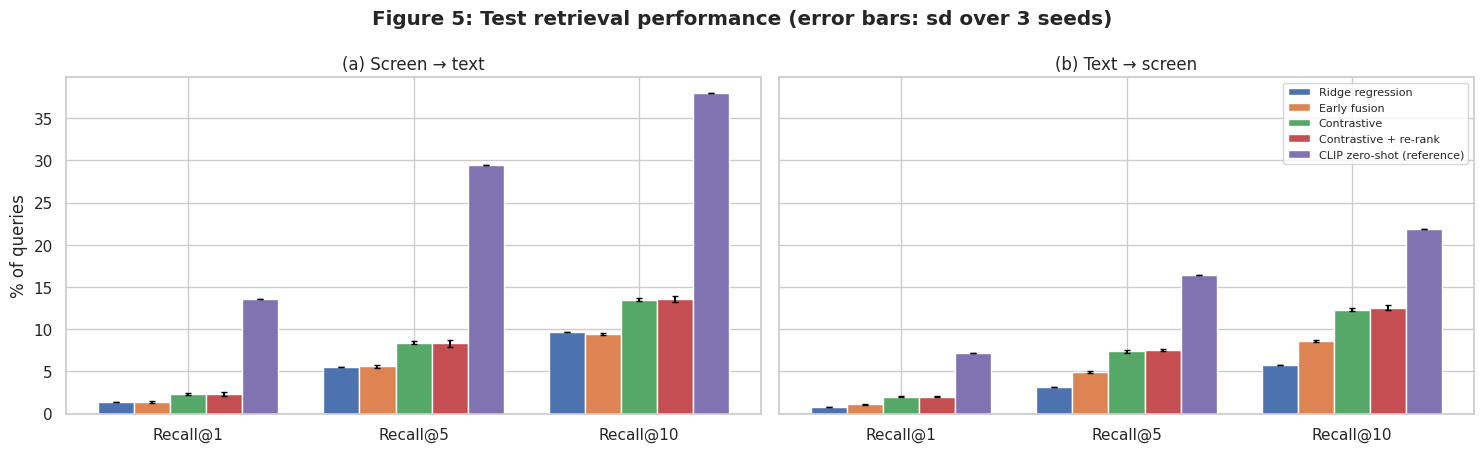

PosixPath('results/figures/fig5_test_results.png')

In [14]:
COLS = ["i2t_R1", "i2t_R5", "i2t_R10", "i2t_MRR", "i2t_MedR", "t2i_R1", "t2i_R5", "t2i_R10", "t2i_MRR", "t2i_MedR", "i2t_R10_relaxed", "t2i_R10_relaxed"]
def agg(method):
    df = pd.DataFrame([{k: v for k, v in m.items() if not k.startswith("_")} for m in TEST[method]])
    return df.mean(), (df.std(ddof=0) if len(df) > 1 else df.mean() * 0)
rows_, summary = [], {}
for method in TEST:
    mu, sd = agg(method); n = len(TEST[method])
    fmt = (lambda c: f"{mu[c]:.2f} ± {sd[c]:.2f}") if n > 1 else (lambda c: f"{mu[c]:.2f}")
    rows_.append({"method": method, **{c: fmt(c) for c in COLS}})
    summary[method] = {c: mu[c] for c in COLS} | {f"{c}_sd": sd[c] for c in COLS}
R.table(pd.DataFrame(rows_).set_index("method"), "t9_test_results",
        "Table 9: test results (Recall in %, MRR 0-1, MedR = median rank; relaxed = identical-caption matches accepted)")
R.rec("test_results", summary, show=False)

LEARNED = ["Early fusion", "Contrastive", "Contrastive + re-rank"]
VAL_SCORE = {"Early fusion": abl_df.set_index("config").loc[BEST_CFG["early"], "_val"],
             "Contrastive": abl_df.set_index("config").loc[BEST_CFG["contrastive"], "_val"],
             "Contrastive + re-rank": grid_df["val_avg_R10"].max()}
R.rec("validation_avg_R10_learned", VAL_SCORE)
best_method = max(LEARNED, key=lambda m: VAL_SCORE[m])
gain = {d: agg(best_method)[0][f"{d}_R10"] - agg("Ridge regression")[0][f"{d}_R10"] for d in ["i2t", "t2i"]}
R.rec("best_learned_method", best_method); R.rec("gain_over_ridge_R10_points", gain)
R.rec("success_criterion_met_point_estimate", all(v >= 5 for v in gain.values()))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
methods = [m for m in TEST if m != "Random"]
for a, d, title in [(ax[0], "i2t", "(a) Screen → text"), (ax[1], "t2i", "(b) Text → screen")]:
    x = np.arange(3); w = 0.8 / len(methods)
    for k, m in enumerate(methods):
        mu, sd = agg(m)
        a.bar(x + k * w, [mu[f"{d}_R{K}"] for K in (1, 5, 10)], w, yerr=[sd[f"{d}_R{K}"] for K in (1, 5, 10)], capsize=2, label=m, color=PALETTE[k % 8])
    a.set_xticks(x + w * (len(methods) - 1) / 2); a.set_xticklabels(["Recall@1", "Recall@5", "Recall@10"]); a.set_title(title)
ax[0].set_ylabel("% of queries"); ax[1].legend(fontsize=8)
fig.suptitle("Figure 5: Test retrieval performance (error bars: sd over 3 seeds)", fontweight="bold"); fig.tight_layout()
R.fig(fig, "fig5_test_results")

## 12. Bootstrap confidence intervals and the success criterion

Test screens are resampled with replacement 1,000 times and a screen's captions move with it (cluster bootstrap; Efron & Tibshirani, 1993). Per-query hits are averaged over the three seeds first. The **paired** difference to ridge on the same resamples tests the proposal's success criterion: **≥ 5 points Recall@10 over ridge in both directions**.

In [15]:
cap2img_np = D["test"]["cap2img"].cpu().numpy()
BS = evaluation.ClusterBootstrap(cap2img_np, N_BOOT, SEED)
HITS = {m: (evaluation.hits_at_k(TEST[m], "i2t"), evaluation.hits_at_k(TEST[m], "t2i")) for m in TEST}
B = {m: BS.samples(*HITS[m]) for m in TEST}
ci = evaluation.ci95
rows_ = []
for m in TEST:
    (li, ui), (lt, ut) = ci(B[m][0]), ci(B[m][1]); pi, pt = BS.point(*HITS[m])
    rows_.append({"method": m, "i2t_R10": f"{pi:.2f} [{li:.2f}, {ui:.2f}]", "t2i_R10": f"{pt:.2f} [{lt:.2f}, {ut:.2f}]"})
for m in LEARNED:
    di, dt = B[m][0] - B["Ridge regression"][0], B[m][1] - B["Ridge regression"][1]
    rows_.append({"method": f"Δ {m} − Ridge", "i2t_R10": f"{di.mean():.2f} [{ci(di)[0]:.2f}, {ci(di)[1]:.2f}]",
                  "t2i_R10": f"{dt.mean():.2f} [{ci(dt)[0]:.2f}, {ci(dt)[1]:.2f}]"})
    R.rec(f"delta_vs_ridge_{m}", {"i2t": [di.mean(), *ci(di)], "t2i": [dt.mean(), *ci(dt)],
                                  "P(delta>=5)_i2t": (di >= 5).mean(), "P(delta>=5)_t2i": (dt >= 5).mean()})
R.table(pd.DataFrame(rows_).set_index("method"), "t10_bootstrap_ci", "Table 10: test Recall@10 with 95% bootstrap confidence intervals")

[result] delta_vs_ridge_Early fusion = {'i2t': [-0.2637, -1.5466, 1.1006], 't2i': [2.9301, 2.0828, 3.7204], 'P(delta>=5)_i2t': 0.0, 'P(delta>=5)_t2i': 0.0}
[result] delta_vs_ridge_Contrastive = {'i2t': [3.8002, 2.468, 5.2041], 't2i': [6.6237, 5.6969, 7.5431], 'P(delta>=5)_i2t': 0.039, 'P(delta>=5)_t2i': 1.0}
[result] delta_vs_ridge_Contrastive + re-rank = {'i2t': [3.842, 2.4383, 5.249], 't2i': [6.8164, 5.8607, 7.7394], 'P(delta>=5)_i2t': 0.053, 'P(delta>=5)_t2i': 1.0}
Table 10: test Recall@10 with 95% bootstrap confidence intervals


,i2t_R10,t2i_R10
method,,
Random,"0.67 [0.36, 1.03]","0.54 [0.41, 0.69]"
Ridge regression,"9.72 [8.47, 10.93]","5.71 [5.04, 6.38]"
Early fusion,"9.43 [8.59, 10.44]","8.64 [7.89, 9.38]"
Contrastive,"13.51 [12.33, 14.75]","12.34 [11.50, 13.21]"
Contrastive + re-rank,"13.54 [12.34, 14.85]","12.53 [11.68, 13.44]"
CLIP zero-shot (reference),"37.96 [35.99, 39.79]","21.93 [20.77, 23.13]"
Δ Early fusion − Ridge,"-0.26 [-1.55, 1.10]","2.93 [2.08, 3.72]"
Δ Contrastive − Ridge,"3.80 [2.47, 5.20]","6.62 [5.70, 7.54]"
Δ Contrastive + re-rank − Ridge,"3.84 [2.44, 5.25]","6.82 [5.86, 7.74]"


## 13. Bias assessment: performance by app category

Recall@10 per category (categories with at least `MIN_CAT_TEST` test screens) with bootstrap intervals, for the best learned model and ridge. **Macro-averaged** recall (mean over categories) weights small categories equally; a large gap to the micro average would mean the headline number hides weak categories. Small test categories give wide intervals, so differences are indicative rather than proof of unfairness.

Table 11: Recall@10 by category (Contrastive + re-rank, 95% CI for text→screen)


,test_screens,i2t_R10,t2i_R10,t2i_lo,t2i_hi
category,,,,,
Medical,53,5.7,7.4,4.0,11.0
Books & Reference,77,5.6,8.4,4.7,12.8
Comics,53,15.7,9.2,5.4,13.6
Finance,74,7.7,9.5,5.8,13.9
Travel & Local,106,6.6,9.7,6.9,12.7
Education,112,14.6,10.0,7.0,13.5
Communication,144,12.7,10.0,6.9,13.3
House & Home,16,18.8,10.5,3.4,18.8
Social,161,11.6,10.8,8.0,13.9


[result] bias_micro_vs_macro = {'Ridge regression': {'micro_i2t': 9.7235, 'micro_t2i': 5.7058, 'macro_i2t': 10.9998, 'macro_t2i': 5.6578, 'worst_category_t2i': ['House & Home', 1.2658], 'best_category_t2i': ['Social', 9.4221]}, 'Contrastive + re-rank': {'micro_i2t': 13.5445, 'micro_t2i': 12.5293, 'macro_i2t': 15.3795, 'macro_t2i': 13.2268, 'worst_category_t2i': ['Medical', 7.3643], 'best_category_t2i': ['Auto & Vehicles', 23.0556]}}
[result] categories_evaluated = 26
[result] corr_category_train_size_vs_t2i_R10 = -0.4367


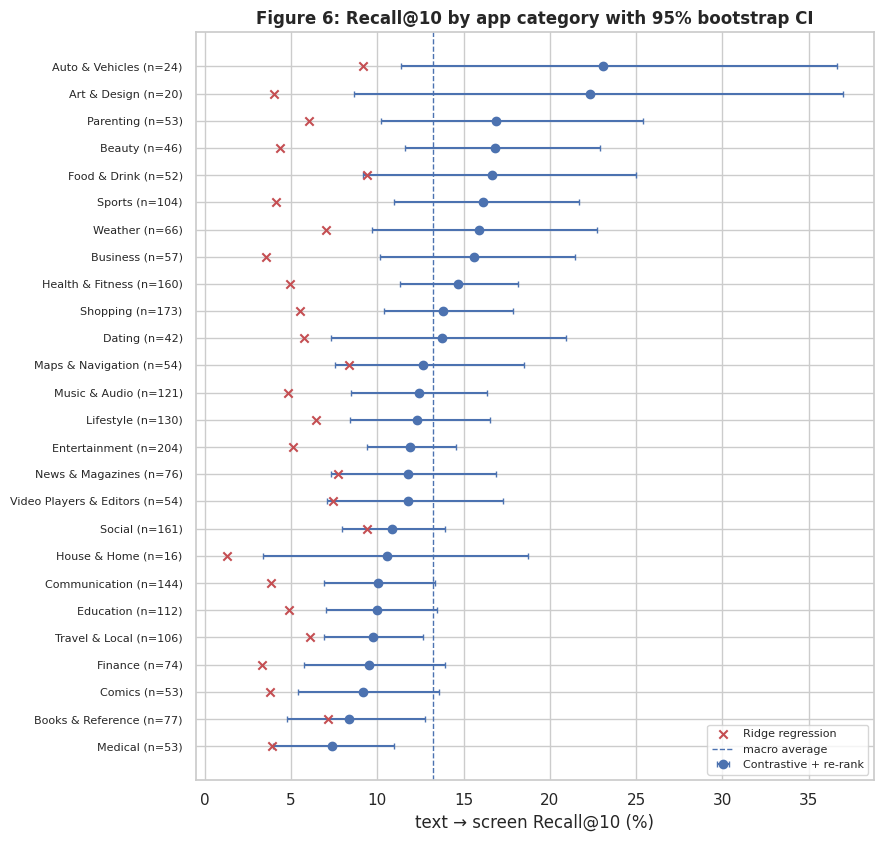

PosixPath('results/figures/fig6_per_category.png')

In [16]:
cats = meta["category_clean"].values[D["test"]["rows"]]
cat_n = pd.Series(cats).value_counts(); cats_ok = cat_n[cat_n >= MIN_CAT_TEST].index
def cat_table(method):
    hi, ht = HITS[method]; rows_ = []
    for c in cats_ok:
        bs = evaluation.ClusterBootstrap(cap2img_np, N_BOOT, SEED, subset=np.where(cats == c)[0])
        pi, pt = bs.point(hi, ht); _, tb = bs.samples(hi, ht)
        rows_.append({"category": c, "test_screens": len(bs.subset), "i2t_R10": pi, "t2i_R10": pt,
                      "t2i_lo": np.percentile(tb, 2.5), "t2i_hi": np.percentile(tb, 97.5)})
    return pd.DataFrame(rows_).set_index("category").sort_values("t2i_R10")
CT = {m: cat_table(m) for m in ["Ridge regression", best_method]}
ct = CT[best_method]
R.table(ct.round(1), "t11_per_category", f"Table 11: Recall@10 by category ({best_method}, 95% CI for text→screen)")
bias = {m: {"micro_i2t": HITS[m][0].mean() * 100, "micro_t2i": BS.point(*HITS[m])[1],
            "macro_i2t": t["i2t_R10"].mean(), "macro_t2i": t["t2i_R10"].mean(),
            "worst_category_t2i": [t["t2i_R10"].idxmin(), t["t2i_R10"].min()],
            "best_category_t2i": [t["t2i_R10"].idxmax(), t["t2i_R10"].max()]} for m, t in CT.items()}
R.rec("bias_micro_vs_macro", bias); R.rec("categories_evaluated", len(cats_ok))
train_cat_n = pd.Series(meta["category_clean"].values[D["train"]["rows"]]).value_counts()
R.rec("corr_category_train_size_vs_t2i_R10", np.corrcoef(train_cat_n.reindex(ct.index).fillna(0), ct["t2i_R10"])[0, 1] if len(ct) > 2 else np.nan)

fig, a = plt.subplots(figsize=(9, max(3.5, 0.33 * len(ct))))
y = np.arange(len(ct))
a.errorbar(ct["t2i_R10"], y, xerr=[ct["t2i_R10"] - ct["t2i_lo"], ct["t2i_hi"] - ct["t2i_R10"]], fmt="o", color=PALETTE[0], capsize=2, label=best_method)
a.scatter(CT["Ridge regression"].reindex(ct.index)["t2i_R10"], y, marker="x", color=PALETTE[3], label="Ridge regression", zorder=3)
a.axvline(bias[best_method]["macro_t2i"], color=PALETTE[0], ls="--", lw=1, label="macro average")
a.set_yticks(y); a.set_yticklabels([f"{c} (n={n})" for c, n in zip(ct.index, ct["test_screens"])], fontsize=8)
a.set_xlabel("text → screen Recall@10 (%)"); a.legend(fontsize=8, loc="lower right")
a.set_title("Figure 6: Recall@10 by app category with 95% bootstrap CI", fontweight="bold"); fig.tight_layout()
R.fig(fig, "fig6_per_category")

## 14. Failure analysis: generic captions

Text→screen recall broken down by how many screens in the whole dataset share the query caption. Generic captions ("login page") fail under the strict metric because several screens are equally correct; the relaxed metric shows whether the model still returns a screen with that caption.

Table 12: text→screen Recall@10 by caption specificity (Contrastive + re-rank)


,captions,strict_R10,relaxed_R10
bin,,,
unique,7539,12.51,12.51
2–5 screens,1627,15.37,17.25
6–20 screens,873,13.71,25.28
>20 screens,1055,7.30,52.23


[result] generic_caption_analysis = {'captions': {'unique': 7539, '2–5 screens': 1627, '6–20 screens': 873, '>20 screens': 1055}, 'strict_R10': {'unique': 12.51, '2–5 screens': 15.37, '6–20 screens': 13.71, '>20 screens': 7.3}, 'relaxed_R10': {'unique': 12.51, '2–5 screens': 17.25, '6–20 screens': 25.28, '>20 screens': 52.23}}


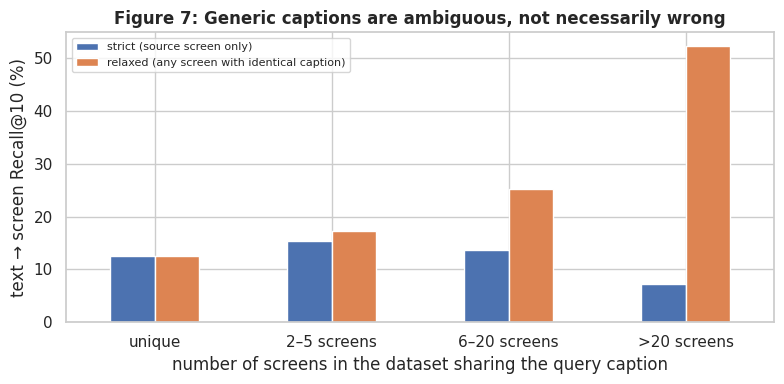

PosixPath('results/figures/fig7_generic_captions.png')

In [17]:
share_te = CI.screens_sharing[D["test"]["cap_ids"]]
bins_ = pd.cut(share_te, [0, 1, 5, 20, 1e9], labels=["unique", "2–5 screens", "6–20 screens", ">20 screens"])
ga = pd.DataFrame({"bin": bins_, "strict": evaluation.hits_at_k(TEST[best_method], "t2i") * 100,
                   "relaxed": evaluation.hits_at_k(TEST[best_method], "t2i", relaxed=True) * 100})
gt = ga.groupby("bin", observed=False).agg(captions=("strict", "size"), strict_R10=("strict", "mean"), relaxed_R10=("relaxed", "mean"))
R.table(gt.round(2), "t12_generic_captions", f"Table 12: text→screen Recall@10 by caption specificity ({best_method})")
R.rec("generic_caption_analysis", gt.round(2).to_dict())
fig, a = plt.subplots(figsize=(8, 4))
gt[["strict_R10", "relaxed_R10"]].plot.bar(ax=a, color=[PALETTE[0], PALETTE[1]], rot=0)
a.set_xlabel("number of screens in the dataset sharing the query caption"); a.set_ylabel("text → screen Recall@10 (%)")
a.legend(["strict (source screen only)", "relaxed (any screen with identical caption)"], fontsize=8)
a.set_title("Figure 7: Generic captions are ambiguous, not necessarily wrong", fontweight="bold"); fig.tight_layout()
R.fig(fig, "fig7_generic_captions")

## 15. Scalability: query cost versus gallery size

Early fusion runs its MLP for every query–candidate pair (the standard, un-factorised head is timed). The contrastive model embeds the gallery once offline, so a query is one matrix product. Re-ranking adds K early-fusion pairs. Costs exclude feature extraction; early-fusion cost is extrapolated linearly from measured pairs per second.

Table 13: ranking cost per query (ms)


,early_fusion_ms,contrastive_ms,contrastive+rerank_ms
gallery_size,,,
1000,0.854,0.273,0.316
10000,8.541,0.277,0.320
100000,85.411,0.537,0.580
1000000,854.111,4.407,4.450


[result] latency_ms = {'early_fusion_ms': {'1000': 0.854, '10000': 8.541, '100000': 85.411, '1000000': 854.111}, 'contrastive_ms': {'1000': 0.273, '10000': 0.277, '100000': 0.537, '1000000': 4.407}, 'contrastive+rerank_ms': {'1000': 0.316, '10000': 0.32, '100000': 0.58, '1000000': 4.45}}
[result] early_fusion_pairs_per_second = 1170807.8932


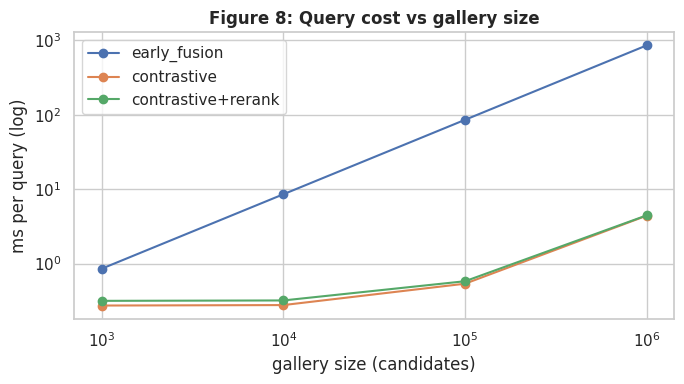

PosixPath('results/figures/fig8_latency.png')

In [18]:
m_e, m_c = RUNS[("early", BEST_CFG["early"], SEEDS[0])]["model"].eval(), RUNS[("contrastive", BEST_CFG["contrastive"], SEEDS[0])]["model"].eval()
xi1, XT_all = D["test"]["XI"][:1], D["test"]["XT"]
with torch.no_grad():
    n_pairs = 200_000 if DEVICE == "cuda" else 20_000
    xt = XT_all[torch.randint(0, len(XT_all), (n_pairs,), device=DEVICE)]
    for _ in range(2): m_e(xi1.expand(n_pairs, -1), xt)
    with timer() as t: m_e(xi1.expand(n_pairs, -1), xt)
    early_pairs_s = n_pairs / t["s"]
    lat = []
    for G in LAT_GALLERIES:
        gal = F.normalize(torch.randn(G, 256, device=DEVICE), dim=-1)
        for _ in range(3): (m_c.enc_t(XT_all[:1]) @ gal.T).topk(10)
        with timer() as t2:
            for _ in range(20): (m_c.enc_t(XT_all[:1]) @ gal.T).topk(10)
        con_ms = t2["s"] / 20 * 1000
        lat.append({"gallery_size": G, "early_fusion_ms": G / early_pairs_s * 1000, "contrastive_ms": con_ms,
                    "contrastive+rerank_ms": con_ms + RR_K / early_pairs_s * 1000})
        del gal
lat_df = pd.DataFrame(lat).set_index("gallery_size")
R.table(lat_df.round(3), "t13_latency", "Table 13: ranking cost per query (ms)")
R.rec("latency_ms", lat_df.round(3).to_dict()); R.rec("early_fusion_pairs_per_second", early_pairs_s)
fig, a = plt.subplots(figsize=(7, 4))
for c, col in zip(lat_df.columns, PALETTE): a.plot(lat_df.index, lat_df[c], "o-", label=c.replace("_ms", ""), color=col)
a.set_xscale("log"); a.set_yscale("log"); a.set_xlabel("gallery size (candidates)"); a.set_ylabel("ms per query (log)")
a.legend(); a.set_title("Figure 8: Query cost vs gallery size", fontweight="bold"); fig.tight_layout()
R.fig(fig, "fig8_latency")

## 16. Sensitivity analysis: near-duplicate threshold

At cosine 0.95, template-like screens chain many apps into one very large group (Table 3) that is kept in training, so the test set holds only screens visually distinct from it and may be harder and less representative. The split is rebuilt with the stricter `SENS_THRESHOLD` (smaller groups, more representative test set), and ridge and the chosen contrastive configuration are retrained (3 seeds) and re-tested.

In [19]:
split2, _, forced_sens = splits.grouped_split(pairs, app_index, SENS_THRESHOLD, MAX_GROUP_SHARE, **kw)
_, L2 = splits.leakage_report(Fn, split2, keep, CI.owner, CI.textid)
lab2 = np.array(["excluded"] * len(meta), dtype=object); lab2[keep] = split2; lab2[meta["pii_excluded"].values] = "excluded"
D2 = split_tensors(ENC, POOL, labels=lab2)
W2, _, _ = fit_ridge(D2, [ALPHA])
m_r2 = evaluation.evaluate(models.ridge_scores(W2, D2["test"]), D2["test"])
m_c2 = [evaluation.evaluate(training.train_model("contrastive", CONFIGS[("contrastive", BEST_CFG["contrastive"])], sd, D2, CI.n_text, EPOCHS, PATIENCE, BATCH)["model"]
                            .score_matrix(D2["test"]["XI"], D2["test"]["XT"]), D2["test"]) for sd in SEEDS]
def sens_row(L, forced, mr, mcs):
    ci_, ct_ = np.mean([m["i2t_R10"] for m in mcs]), np.mean([m["t2i_R10"] for m in mcs])
    return {"screens forced to train": forced, "test screens": L["test_screens"], "test near-dup in train >0.95 (%)": L["near_dup_in_train_>0.95_%"],
            "ridge i2t R@10": mr["i2t_R10"], "ridge t2i R@10": mr["t2i_R10"], "contrastive i2t R@10": ci_, "contrastive t2i R@10": ct_,
            "gain i2t": ci_ - mr["i2t_R10"], "gain t2i": ct_ - mr["t2i_R10"]}
sens_tbl = pd.DataFrame([sens_row(L_grp, forced_main, TEST["Ridge regression"][0], TEST["Contrastive"]), sens_row(L2, forced_sens, m_r2, m_c2)],
                        index=[f"main (cos>{DUP_THRESHOLD})", f"sensitivity (cos>{SENS_THRESHOLD})"]).round(2)
R.table(sens_tbl, "t14_sensitivity_threshold", "Table 14: sensitivity of the comparison to the near-duplicate threshold (contrastive = mean of 3 seeds)")
R.rec("sensitivity_threshold", sens_tbl.to_dict(orient="index"))
del D2, Fn; gc.collect()

Table 14: sensitivity of the comparison to the near-duplicate threshold (contrastive = mean of 3 seeds)


,screens forced to train,test screens,test near-dup in train >0.95 (%),ridge i2t R@10,ridge t2i R@10,contrastive i2t R@10,contrastive t2i R@10,gain i2t,gain t2i
main (cos>0.95),13822,2242,0.00,9.72,5.71,13.51,12.34,3.79,6.63
sensitivity (cos>0.98),1188,2254,17.52,8.97,5.97,13.71,13.40,4.74,7.42


[result] sensitivity_threshold = {'main (cos>0.95)': {'screens forced to train': 13822, 'test screens': 2242, 'test near-dup in train >0.95 (%)': 0.0, 'ridge i2t R@10': 9.72, 'ridge t2i R@10': 5.71, 'contrastive i2t R@10': 13.51, 'contrastive t2i R@10': 12.34, 'gain i2t': 3.79, 'gain t2i': 6.63}, 'sensitivity (cos>0.98)': {'screens forced to train': 1188, 'test screens': 2254, 'test near-dup in train >0.95 (%)': 17.52, 'ridge i2t R@10': 8.97, 'ridge t2i R@10': 5.97, 'contrastive i2t R@10': 13.71, 'contrastive t2i R@10': 13.4, 'gain i2t': 4.74, 'gain t2i': 7.42}}


18310

## 17. Qualitative examples (private)

Top-5 text→screen results for random test captions, skipping screens with login, payment or messaging functions. Contains screenshots, so it is saved only to the git-ignored `private_outputs/`.

In [20]:
def show_examples(n_q=4, k=5, seed=3):
    S = m_c.score_matrix(D["test"]["XI"], D["test"]["XT"])
    safe = ~meta["sensitive_function"].values[D["test"]["rows"]]
    cand = [q for q in range(S.shape[1]) if safe[int(D["test"]["cap2img"][q])]]
    qs = np.random.default_rng(seed).choice(cand, n_q, replace=False)
    fig, axes = plt.subplots(n_q, k + 1, figsize=(2.3 * (k + 1), 3.9 * n_q))
    for qi, q in enumerate(qs):
        axes[qi, 0].axis("off"); axes[qi, 0].text(0, 0.5, textwrap.fill(CI.caps[D["test"]["cap_ids"][q]], 26), fontsize=9, va="center")
        top = S[:, q].topk(k).indices.cpu().numpy(); true_i = int(D["test"]["cap2img"][q])
        for j, idx in enumerate(top):
            a = axes[qi, j + 1]; a.imshow(ds_img[int(D["test"]["rows"][idx])][IMG_COL].convert("RGB").resize((180, 320)))
            a.set_xticks([]); a.set_yticks([])
            for sp in a.spines.values(): sp.set_edgecolor("#2ca02c" if idx == true_i else "#d62728"); sp.set_linewidth(4)
            a.set_title(f"rank {j + 1}", fontsize=8)
    fig.suptitle("Text→screen examples (contrastive; green = source screen)", fontweight="bold"); fig.tight_layout()
    R.fig(fig, "qualitative_examples", private=True)
show_examples()

[screenshot figure saved to private_outputs/ only; not shown, because screenshots may be copyrighted or contain personal data]


## 18. Save results

Writes `results/results.json` (every number above) and `results/RESULTS.md` (main tables in Markdown), and offers a zip of `results/` for download.

In [21]:
R.rec("config", {"DATASET_ID": DATASET_ID, "SEEDS": SEEDS, "IMAGE_ENCODERS": IMAGE_ENCODERS, "DUP_THRESHOLD": DUP_THRESHOLD,
                 "SENS_THRESHOLD": SENS_THRESHOLD, "MAX_GROUP_SHARE": MAX_GROUP_SHARE, "EPOCHS": EPOCHS, "PATIENCE": PATIENCE,
                 "BATCH": BATCH, "MAX_LEN": MAX_LEN, "configs": {f"{k[0]}|{k[1]}": v for k, v in CONFIGS.items()},
                 "excluded_screen_ids": EXCLUDE_SCREEN_IDS}, show=False)
R.save_json()
def md(df):
    try: return df.to_markdown()
    except Exception: return "```\n" + df.to_string() + "\n```"
with open(R.out / "RESULTS.md", "w") as f:
    f.write("# Results\n\nGenerated by `s2w_retrieval.ipynb`.\n\n")
    for title, name in [("Test results", "t9_test_results"), ("95% bootstrap confidence intervals", "t10_bootstrap_ci"),
                        ("Feature extraction selection", "t6_feature_selection"), ("Configuration ablation and overfitting", "t7_ablation_overfitting"),
                        ("Leakage", "t4_leakage"), ("Query cost (ms)", "t13_latency"), ("Sensitivity to the near-duplicate threshold", "t14_sensitivity_threshold")]:
        f.write(f"## {title}\n\n{md(pd.read_csv(R.tab / f'{name}.csv', index_col=[0, 1] if name == 't6_feature_selection' else 0))}\n\n")
print(f"Image encoder: {ENC}, pooling: {POOL}; best learned model: {best_method}")
print(f"Recall@10 gain over ridge: screen→text {gain['i2t']:.2f}, text→screen {gain['t2i']:.2f} points")
if IN_COLAB:
    import shutil
    from google.colab import files
    shutil.make_archive("results", "zip", ".", "results"); files.download("results.zip")

Image encoder: vit_b_16, pooling: mean; best learned model: Contrastive + re-rank
Recall@10 gain over ridge: screen→text 3.82, text→screen 6.82 points


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>